# Trabalho Prático - Análise de Sinistros de Trânsito em SP

**Tema Escolhido:** Análise dos veículos envolvidos em acidentes (sinistros) de trânsito no estado de São Paulo.

**Origem e Significado dos Dados:** Os dados foram extraídos do portal de Dados Abertos do Estado de São Paulo. Cada registro representa um veículo envolvido em um acidente de trânsito, contendo atributos como a marca/modelo, o ano de fabricação, o tipo de veículo, a cor e a data do sinistro.

**Etapas de Tratamento Realizadas:**
1. **Python Nativo:** Leitura e organização inicial dos dados usando estruturas nativas do Python (Listas de Dicionários).
2. **NumPy:** Extração, fatiamento (slicing) e cálculos estatísticos (média, min, max, desvio) baseados no ano de fabricação.
3. **Pandas:** Criação de um DataFrame agrupando arquivos CSV, realizando limpeza profunda (remoção de valores ausentes/inválidos), filtragem de tipos e ordenação.
4. **Matplotlib:** Geração de gráficos ilustrativos com base nos dados previamente tratados.


In [16]:
import os
import csv
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definindo a pasta com os dados
PASTA_DADOS = 'dados_sinistros'
# Pegando apenas o primeiro arquivo para a primeira etapa (Python Nativo)
arquivos_csv = glob.glob(os.path.join(PASTA_DADOS, '*.csv'))
arquivo_exemplo = arquivos_csv[0] if arquivos_csv else None


## 1. Organização inicial dos dados (Python Nativo)
Vamos abrir o primeiro arquivo CSV e ler as primeiras linhas utilizando as estruturas nativas do Python. Armazenaremos os dados em uma **lista de dicionários**.


In [17]:
# Utilização de estruturas de dados nativas (Lista de dicionários)
dados_nativos = []

if arquivo_exemplo:
    with open(arquivo_exemplo, mode='r', encoding='latin-1') as f:
        leitor = csv.DictReader(f, delimiter=';')
        
        # Lendo apenas as primeiras 1000 linhas para demonstração
        for i, linha in enumerate(leitor):
            if i >= 1000:
                break
            dados_nativos.append(dict(linha))

# Exibindo o primeiro registro para confirmar o formato
print("Registro armazenado no dicionário:")
print(dados_nativos[0])


Registro armazenado no dicionário:
{'id_sinistro': '1613672', 'id_veiculo': '608005', 'marca_modelo': '', 'ano_fab': '', 'ano_modelo': '', 'cor_veiculo': '', 'tipo_veiculo': 'NAO DISPONIVEL', 'data_sinistro': '01/01/2021', 'ano_sinistro': '2021', 'mes_sinistro': '01', 'dia_sinistro': '01', 'ano_mes_sinistro': '2021/01'}


## 2. Utilização do NumPy
A partir da nossa lista de dicionários, extrairemos o `ano_fab` (ano de fabricação) dos veículos, converteremos para um **array NumPy** e realizaremos operações numéricas básicas (média, mínimo, máximo, desvio padrão). Ignoraremos registros onde a idade é inválida ou vazia.


In [18]:
# Extraindo os anos de fabricação, ignorando valores vazios ou lixo
anos_fabricacao = []
for reg in dados_nativos:
    ano_str = reg.get('ano_fab', '')
    if ano_str.isdigit():
        anos_fabricacao.append(int(ano_str))

# Criação/conversão para array NumPy
anos_array = np.array(anos_fabricacao)

print(f"Total de anos de fabricação válidos no array: {len(anos_array)}")

if len(anos_array) > 0:
    # Acesso a elementos e subconjuntos via Slicing (exibindo os 10 primeiros elementos)
    print("Primeiros 10 elementos (slicing):", anos_array[:10])

    # Operações NumPy
    media_ano = np.mean(anos_array)
    max_ano = np.max(anos_array)
    min_ano = np.min(anos_array)
    desvio = np.std(anos_array)

    print("\n--- Resultados Numéricos (NumPy) ---")
    print(f"Média do ano de fabricação: {media_ano:.2f}")
    print(f"Ano mais antigo (Mínimo): {min_ano}")
    print(f"Ano mais novo (Máximo): {max_ano}")
    print(f"Desvio-padrão: {desvio:.2f}")


Total de anos de fabricação válidos no array: 790
Primeiros 10 elementos (slicing): [2016 2007 2019 2014 1995 2016 2001 1993 2008 1987]

--- Resultados Numéricos (NumPy) ---
Média do ano de fabricação: 2009.35
Ano mais antigo (Mínimo): 1975
Ano mais novo (Máximo): 2021
Desvio-padrão: 8.11


## 3. Utilização do Pandas
Para aprofundar nossa análise e demonstrar um tratamento robusto, vamos importar os dados de **meses inteiros** diretamente para um DataFrame do Pandas. Faremos:
- **Importação/Criação:** Carregamento de múltiplos CSVs.
- **Identificação de dados inválidos:** Mapeamento do que está ausente (NaN).
- **Tratamento:** Remoção de NA e descarte de lixo (como "NAO DISPONIVEL").
- **Filtragem, Seleção e Ordenação.**
- **Estatísticas Agregadas.**


In [19]:
# Vamos carregar os 3 primeiros meses de dados
arquivos_selecionados = sorted(arquivos_csv)[:3]
lista_dfs = []

for arquivo in arquivos_selecionados:
    df_temp = pd.read_csv(arquivo, sep=';', encoding='latin-1', low_memory=False)
    lista_dfs.append(df_temp)

# Criação do DataFrame unificado
df = pd.concat(lista_dfs, ignore_index=True)

# 1. Identificação de dados ausentes ou inválidos
print("Total de Valores ausentes por coluna (antes da limpeza):")
print(df.isna().sum())

# Vamos injetar um dado inválido proposital apenas para garantir demonstração, 
# caso a base já não fosse super suja por natureza:
df.loc[0, 'ano_fab'] = 9999 

# 2. Remoção ou tratamento desses dados (Limpando o Dataset)
# Removendo linhas onde não se sabe o tipo do veículo ou ano
df_limpo = df.dropna(subset=['tipo_veiculo', 'ano_fab']).copy()

# Removendo texto inválido (NAO DISPONIVEL)
df_limpo = df_limpo[df_limpo['tipo_veiculo'] != 'NAO DISPONIVEL']

# Forçando o tipo numérico no ano e descartando o que não converter e valores bizarros
df_limpo['ano_fab'] = pd.to_numeric(df_limpo['ano_fab'], errors='coerce')
df_limpo = df_limpo.dropna(subset=['ano_fab'])
df_limpo = df_limpo[(df_limpo['ano_fab'] >= 1950) & (df_limpo['ano_fab'] <= 2025)]
df_limpo['ano_fab'] = df_limpo['ano_fab'].astype(int)

# 3. Seleção de colunas úteis
df_limpo = df_limpo[['tipo_veiculo', 'cor_veiculo', 'ano_fab', 'marca_modelo']]

# 4. Filtragem e Ordenação: Apenas utilitários ou automóveis, ordenados do mais novo para o antigo
# Filtragem
df_carros = df_limpo[df_limpo['tipo_veiculo'].isin(['AUTOMOVEL', 'UTILITARIO'])].copy()
# Ordenação
df_carros = df_carros.sort_values(by='ano_fab', ascending=False)

print(f"\nTotal de registros após limpeza e filtragem: {df_carros.shape[0]}")

# 5. Cálculos de informações estatísticas e agregadas
contagem_tipos = df_limpo['tipo_veiculo'].value_counts()
print("\n1. Contagem agrupada (Top 5 tipos de veículos mais envolvidos):")
print(contagem_tipos.head())

idade_carros = 2024 - df_carros['ano_fab']
print(f"\n2. Idade Média dos Carros (Automóveis/Utilitários): {idade_carros.mean():.1f} anos")


Total de Valores ausentes por coluna (antes da limpeza):
id_sinistro             0
id_veiculo              0
marca_modelo         4100
ano_fab             10090
ano_modelo          10439
cor_veiculo          9704
tipo_veiculo            0
data_sinistro           0
ano_sinistro            0
mes_sinistro            0
dia_sinistro            0
ano_mes_sinistro        0
dtype: int64

Total de registros após limpeza e filtragem: 19718

1. Contagem agrupada (Top 5 tipos de veículos mais envolvidos):
tipo_veiculo
AUTOMOVEL      19718
MOTOCICLETA    16984
CAMINHAO        1757
OUTROS           909
ONIBUS           842
Name: count, dtype: int64

2. Idade Média dos Carros (Automóveis/Utilitários): 14.9 anos


## 4. Visualização com Matplotlib
Nesta etapa, utilizaremos o Matplotlib para produzir 3 gráficos, compreendendo 3 representações distintas: **Gráfico de Barras**, **Histograma** e **Gráfico de Dispersão / Pizza**, com a presença de títulos, eixos e legendas.


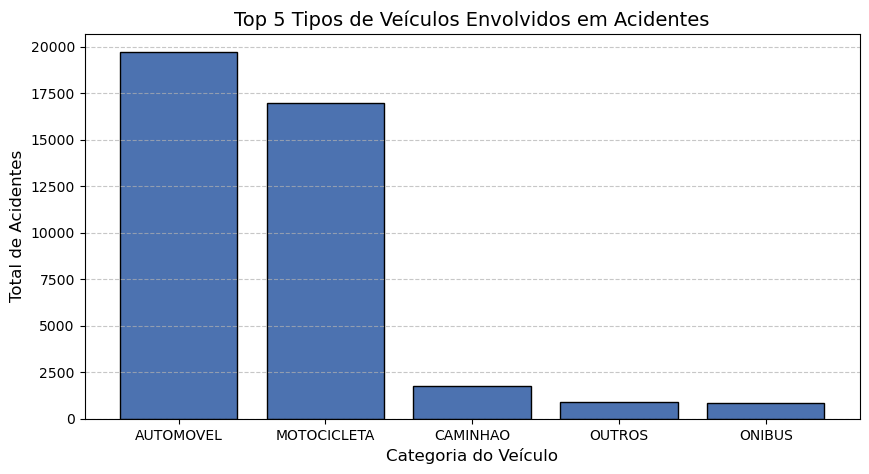

In [20]:
# Gráfico 1: Gráfico de Barras - Top 5 tipos de veículos envolvidos
plt.figure(figsize=(10, 5))
top_5 = contagem_tipos.head(5)

plt.bar(top_5.index, top_5.values, color='#4C72B0', edgecolor='black')
plt.title('Top 5 Tipos de Veículos Envolvidos em Acidentes', fontsize=14)
plt.xlabel('Categoria do Veículo', fontsize=12)
plt.ylabel('Total de Acidentes', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


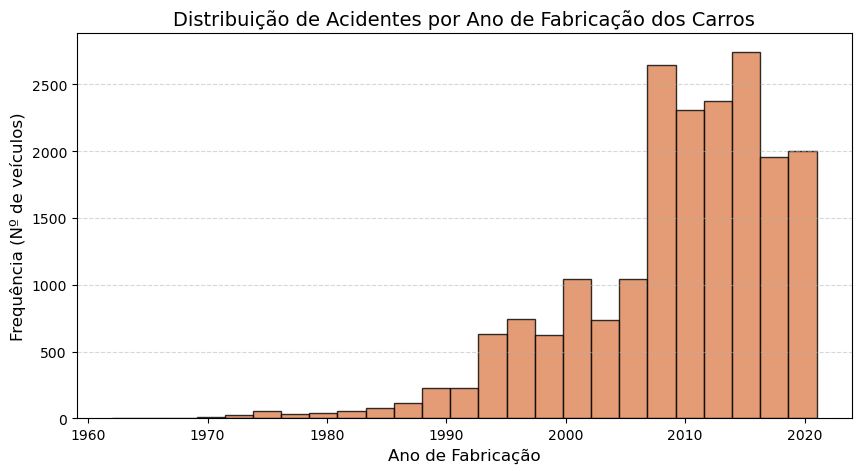

In [21]:
# Gráfico 2: Histograma - Distribuição por Ano de Fabricação (Automóveis)
plt.figure(figsize=(10, 5))
plt.hist(df_carros['ano_fab'], bins=25, color='#DD8452', edgecolor='black', alpha=0.8)

plt.title('Distribuição de Acidentes por Ano de Fabricação dos Carros', fontsize=14)
plt.xlabel('Ano de Fabricação', fontsize=12)
plt.ylabel('Frequência (Nº de veículos)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


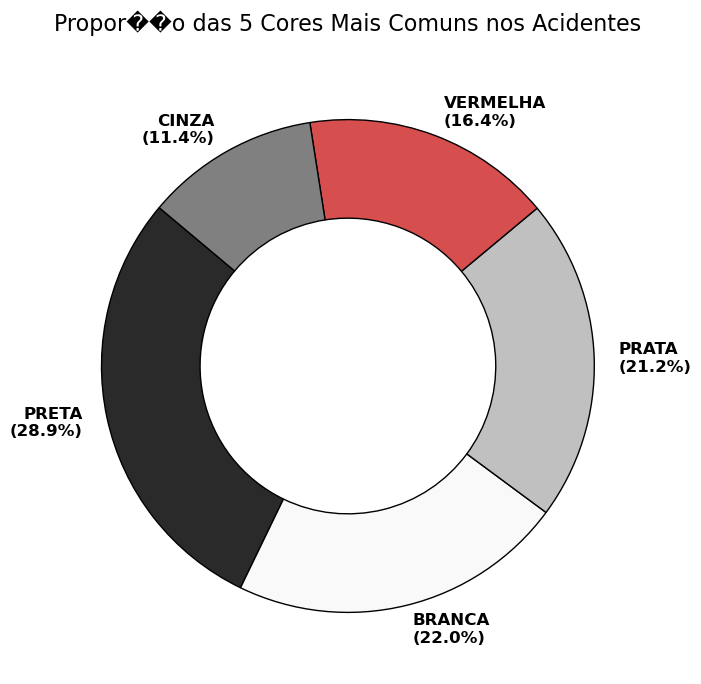

In [23]:
# Gr�fico 3: Gr�fico de Setores (Donut) - Propor��o de Cores
plt.figure(figsize=(9, 8))

# Limpando cores irrelevantes para o gr�fico
df_cores = df_limpo[~df_limpo['cor_veiculo'].isin(['NAO DISPONIVEL', 'OUTRA', 'INDEFINIDA'])]
top_cores = df_cores['cor_veiculo'].value_counts().head(5)

# Dicion�rio mapeando a cor real para a visualiza��o
mapa_cores = {
    'PRETA': '#2A2A2A',   # Preto/Cinza bem escuro
    'BRANCA': '#F9F9F9',  # Branco meio gelo
    'PRATA': '#C0C0C0',   # Prata cl�ssico
    'VERMELHA': '#D64E4E',# Vermelho
    'CINZA': '#808080'    # Cinza m�dio
}

# Criando a lista de cores
cores_grafico = [mapa_cores.get(cor, '#999999') for cor in top_cores.index]

# Unindo os nomes das cores com suas respectivas porcentagens para exibir do lado de fora
total = top_cores.sum()
labels_com_porcentagem = [f"{cor}\n({(val/total)*100:.1f}%)" for cor, val in top_cores.items()]

# Gr�fico de Donut com os textos fora da pizza
plt.pie(
    top_cores.values, 
    labels=labels_com_porcentagem, 
    startangle=140, 
    colors=cores_grafico, 
    labeldistance=1.1, # Dist�ncia do texto para o centro
    textprops={'fontsize': 12, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'width': 0.4}
)

plt.title('Propor��o das 5 Cores Mais Comuns nos Acidentes', fontsize=16, pad=20)
plt.show()